# Notebook 05 — Model Comparison

This notebook aggregates existing model outputs without retraining models or scanning test thresholds. It separates the core RQ2 comparison, the five-model default benchmark, and boosting-only Threshold Sensitivity Analysis.


## 1. Imports and explicit reporting scopes


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

CORE_MODEL_ORDER = ["Logistic Regression", "Random Forest", "XGBoost"]
DEFAULT_BENCHMARK_ORDER = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM", "CatBoost"]
BOOSTING_MODEL_ORDER = ["XGBoost", "LightGBM", "CatBoost"]
EXPECTED_SELECTED_THRESHOLDS = {"XGBoost": 0.38, "LightGBM": 0.27, "CatBoost": 0.38}
METRIC_COLUMNS = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
CONFUSION_COLUMNS = ["TP", "FP", "TN", "FN"]
RECALL_TARGET = 0.85
FIGURE_DPI = 300
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = FIGURE_DPI


## 2. Paths and notebook-local helpers


In [2]:
def find_source_root(start_path: Path) -> Path:
    current = start_path.resolve()
    for candidate in [current, *current.parents]:
        if candidate.name == "Source":
            return candidate
        nested = candidate / "Source"
        if nested.exists() and nested.is_dir():
            return nested.resolve()
    raise FileNotFoundError("Could not locate Source.")


CURRENT_WORKING_DIRECTORY = Path.cwd().resolve()
SOURCE_ROOT = find_source_root(CURRENT_WORKING_DIRECTORY)
REPO_ROOT = SOURCE_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from Source.src.path import DATA_REPORTS_DIR, FIGURES_DIR

DATA_REPORTS_DIR = Path(DATA_REPORTS_DIR)
FIGURES_DIR = Path(FIGURES_DIR)
if not DATA_REPORTS_DIR.exists() or not FIGURES_DIR.exists():
    raise FileNotFoundError("Required report output folders are missing.")

COLUMN_VARIANTS = {
    "Model": ["Model", "model"],
    "Dataset": ["Dataset", "dataset", "Split", "split"],
    "Threshold": ["Threshold", "threshold", "Selected Threshold", "Selected_Threshold", "selected_threshold"],
    "Accuracy": ["Accuracy", "accuracy"],
    "Precision": ["Precision", "precision"],
    "Recall": ["Recall", "recall"],
    "F1": ["F1", "F1-score", "F1_Score", "f1", "f1_score"],
    "ROC_AUC": ["ROC-AUC", "ROC_AUC", "roc_auc"],
    "PR_AUC": ["PR-AUC", "PR_AUC", "pr_auc"],
    "TP": ["TP", "tp"], "FP": ["FP", "fp"], "TN": ["TN", "tn"], "FN": ["FN", "fn"],
    "FPR": ["FPR", "False Positive Rate", "False_Positive_Rate", "false_positive_rate"],
    "FNR": ["FNR", "False Negative Rate", "False_Negative_Rate", "false_negative_rate"],
    "Meets_Recall_Target": ["Meets Recall Target", "Meets_Recall_Target", "Recall_Target_Met", "meets_recall_target"],
    "Target_Recall": ["Target_Recall", "Target Recall", "target_recall"],
    "Selection_Rule": ["Selection_Rule", "Selection Rule", "selection_rule"],
    "Threshold_Source": ["Threshold_Source", "Threshold Source", "threshold_source"],
}
NORMALIZED_COLUMNS = [
    "Model", "Dataset", "Evaluation_Type", "Threshold", "Accuracy", "Precision", "Recall", "F1",
    "ROC_AUC", "PR_AUC", "TP", "FP", "TN", "FN", "FPR", "FNR",
    "Meets_Recall_Target", "Target_Recall", "Selection_Rule", "Threshold_Source",
]


def load_explicit(filename: str) -> pd.DataFrame:
    path = DATA_REPORTS_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing required input: {path}")
    frame = pd.read_csv(path)
    if frame.empty:
        raise ValueError(f"Required input is empty: {path}")
    return frame


def normalize_metrics(df: pd.DataFrame, model: str, dataset: str, evaluation_type: str) -> pd.DataFrame:
    normalized = pd.DataFrame(index=df.index)
    for target, variants in COLUMN_VARIANTS.items():
        source = next((column for column in variants if column in df.columns), None)
        normalized[target] = df[source] if source else np.nan
    normalized["Model"] = normalized["Model"].fillna(model).astype(str)
    normalized["Dataset"] = normalized["Dataset"].fillna(dataset).astype(str).str.lower()
    normalized["Evaluation_Type"] = evaluation_type
    for column in ["Threshold", *METRIC_COLUMNS, *CONFUSION_COLUMNS, "FPR", "FNR", "Target_Recall"]:
        normalized[column] = pd.to_numeric(normalized[column], errors="coerce")
    return normalized[NORMALIZED_COLUMNS].reset_index(drop=True)


def ordered_concat(frames: list[pd.DataFrame], order: list[str]) -> pd.DataFrame:
    result = pd.concat(frames, ignore_index=True)
    result["Model"] = pd.Categorical(result["Model"], categories=order, ordered=True)
    return result.sort_values(["Model", "Threshold"]).reset_index(drop=True)


def assert_scope(df: pd.DataFrame, expected_order: list[str], name: str, one_row_per_model: bool = True) -> None:
    models = df["Model"].astype(str).drop_duplicates().tolist()
    if models != expected_order:
        raise ValueError(f"{name} model scope mismatch: {models}")
    if one_row_per_model and len(df) != len(expected_order):
        raise ValueError(f"{name} expected {len(expected_order)} rows, got {len(df)}")


def save_table(df: pd.DataFrame, filename: str, title: str) -> Path:
    path = DATA_REPORTS_DIR / filename
    df.to_csv(path, index=False)
    print(f"{title}: shape={df.shape}; saved={path}")
    display(df)
    return path


def save_figure(filename: str) -> Path:
    path = FIGURES_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved 300-DPI figure: {path}")
    display(plt.gcf())
    plt.close()
    return path


def plot_metric_benchmark(df: pd.DataFrame, model_order: list[str], title: str) -> None:
    plot_df = df.copy()
    plot_df["Model"] = plot_df["Model"].astype(str)
    plot_df = plot_df.set_index("Model").loc[model_order, METRIC_COLUMNS]
    ax = plot_df.plot(kind="bar", figsize=(12, 6.5), width=0.84)
    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel("Metric value")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="lower right", ncol=2)
    plt.xticks(rotation=0)


## 3. Explicit input mappings


In [3]:
DEFAULT_VALIDATION_FILES = {
    "Logistic Regression": "logistic_default_threshold_validation_metrics.csv",
    "Random Forest": "random_forest_default_threshold_validation_metrics.csv",
    "XGBoost": "xgboost_default_threshold_validation_metrics.csv",
    "LightGBM": "lightgbm_default_threshold_validation_metrics.csv",
    "CatBoost": "catboost_default_threshold_validation_metrics.csv",
}
BOOSTING_THRESHOLD_FILES = {
    "XGBoost": "xgboost_threshold_sensitivity_validation.csv",
    "LightGBM": "lightgbm_threshold_sensitivity_validation.csv",
    "CatBoost": "catboost_threshold_sensitivity_validation.csv",
}
BOOSTING_SELECTED_VALIDATION_FILES = {
    "XGBoost": "xgboost_selected_threshold_validation_metrics.csv",
    "LightGBM": "lightgbm_selected_threshold_validation_metrics.csv",
    "CatBoost": "catboost_selected_threshold_validation_metrics.csv",
}
BOOSTING_SELECTED_TEST_FILES = {
    "XGBoost": "xgboost_selected_threshold_test_metrics.csv",
    "LightGBM": "lightgbm_selected_threshold_test_metrics.csv",
    "CatBoost": "catboost_selected_threshold_test_metrics.csv",
}

explicit_inputs = {
    **DEFAULT_VALIDATION_FILES,
    **{f"{model} threshold": path for model, path in BOOSTING_THRESHOLD_FILES.items()},
    **{f"{model} selected validation": path for model, path in BOOSTING_SELECTED_VALIDATION_FILES.items()},
    **{f"{model} selected test": path for model, path in BOOSTING_SELECTED_TEST_FILES.items()},
}
display(pd.DataFrame([{"Logical input": key, "Filename": value, "Exists": (DATA_REPORTS_DIR / value).exists()} for key, value in explicit_inputs.items()]))
if not all((DATA_REPORTS_DIR / value).exists() for value in explicit_inputs.values()):
    raise FileNotFoundError("One or more explicitly mapped model outputs are missing.")


,Logical input,Filename,Exists
0,Logistic Regression,logistic_default_threshold_validation_metrics.csv,True
1,Random Forest,random_forest_default_threshold_validation_met...,True
2,XGBoost,xgboost_default_threshold_validation_metrics.csv,True
3,LightGBM,lightgbm_default_threshold_validation_metrics.csv,True
4,CatBoost,catboost_default_threshold_validation_metrics.csv,True
5,XGBoost threshold,xgboost_threshold_sensitivity_validation.csv,True
6,LightGBM threshold,lightgbm_threshold_sensitivity_validation.csv,True
7,CatBoost threshold,catboost_threshold_sensitivity_validation.csv,True
8,XGBoost selected validation,xgboost_selected_threshold_validation_metrics.csv,True
9,LightGBM selected validation,lightgbm_selected_threshold_validation_metrics...,True


## 4. Section A — Core RQ2 Default Comparison


In [4]:
default_tables = {
    model: normalize_metrics(load_explicit(filename), model, "validation", "default_threshold")
    for model, filename in DEFAULT_VALIDATION_FILES.items()
}
core_research_default = ordered_concat([default_tables[model] for model in CORE_MODEL_ORDER], CORE_MODEL_ORDER)
assert_scope(core_research_default, CORE_MODEL_ORDER, "Core RQ2 default comparison")
if not np.allclose(core_research_default["Threshold"], 0.50):
    raise ValueError("Core RQ2 comparison must use threshold 0.50 only.")
save_table(core_research_default, "core_research_default_threshold_validation_comparison.csv", "Core RQ2 default-threshold validation comparison")


Core RQ2 default-threshold validation comparison: shape=(3, 20); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\core_research_default_threshold_validation_comparison.csv


,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target,Target_Recall,Selection_Rule,Threshold_Source
0,Logistic Regression,validation,default_threshold,0.5,0.759470,0.530660,0.803571,0.639205,0.854773,0.665839,225,199,577,55,0.256443,0.196429,NaN,NaN,NaN,NaN
1,Random Forest,validation,default_threshold,0.5,0.790720,0.629956,0.510714,0.564103,0.845214,0.645568,143,84,692,137,0.108247,0.489286,NaN,NaN,NaN,NaN
2,XGBoost,validation,default_threshold,0.5,0.761364,0.533493,0.796429,0.638968,0.854375,0.665582,223,195,581,57,0.251289,0.203571,NaN,NaN,NaN,NaN


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/core_research_default_threshold_validation_comparison.csv')

## 5. Section B — Five-Model Default Benchmark


Five-model default-threshold validation benchmark: shape=(5, 20); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\five_model_default_threshold_validation_benchmark.csv


,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target,Target_Recall,Selection_Rule,Threshold_Source
0,Logistic Regression,validation,default_threshold,0.5,0.759470,0.530660,0.803571,0.639205,0.854773,0.665839,225,199,577,55,0.256443,0.196429,NaN,NaN,NaN,NaN
1,Random Forest,validation,default_threshold,0.5,0.790720,0.629956,0.510714,0.564103,0.845214,0.645568,143,84,692,137,0.108247,0.489286,NaN,NaN,NaN,NaN
2,XGBoost,validation,default_threshold,0.5,0.761364,0.533493,0.796429,0.638968,0.854375,0.665582,223,195,581,57,0.251289,0.203571,NaN,NaN,NaN,NaN
3,LightGBM,validation,default_threshold,0.5,0.779356,0.562334,0.757143,0.645358,0.848523,0.651637,212,165,611,68,0.212629,0.242857,NaN,NaN,NaN,NaN
4,CatBoost,validation,default_threshold,0.5,0.764205,0.538272,0.778571,0.636496,0.850150,0.655526,218,187,589,62,0.240979,0.221429,NaN,NaN,NaN,NaN


Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_comparison_01_five_model_default_threshold_validation_metrics.png


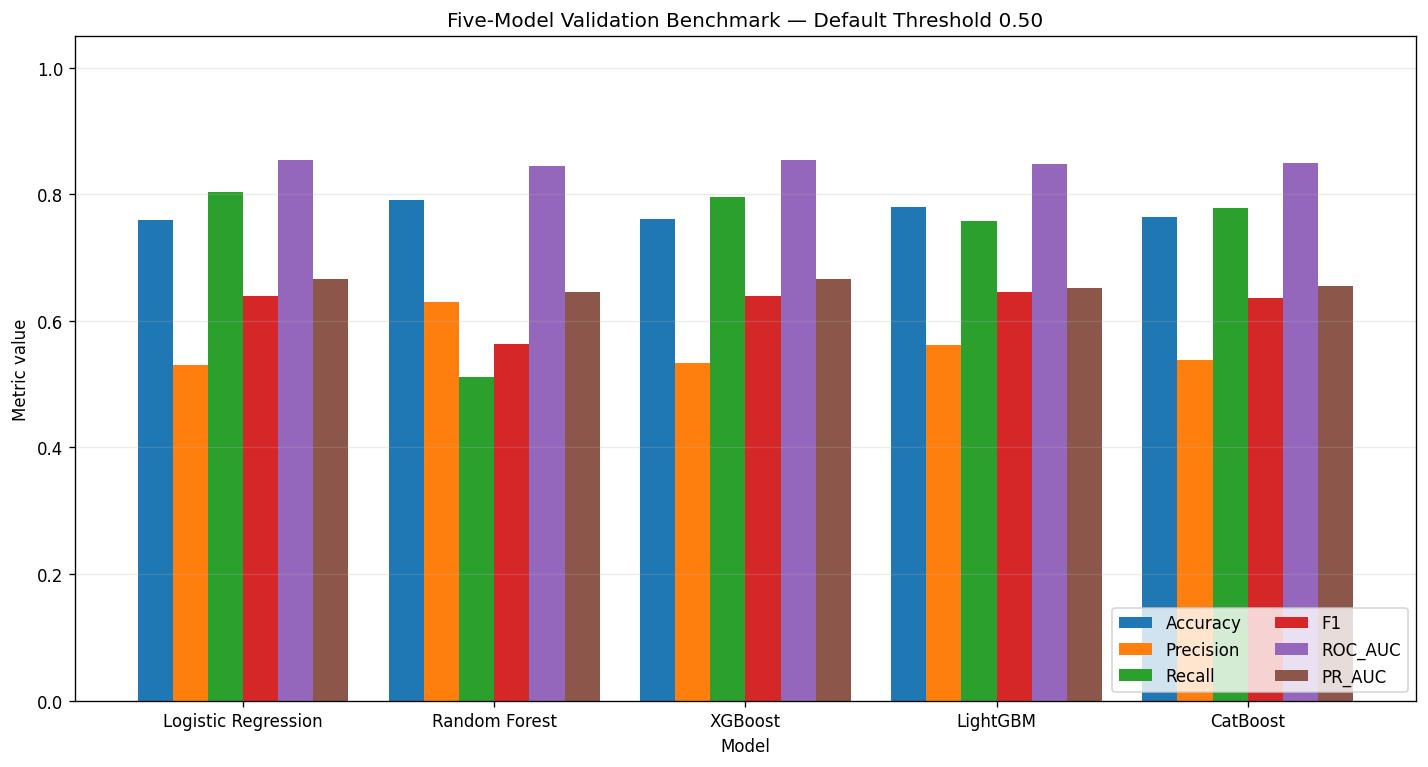

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/model_comparison_01_five_model_default_threshold_validation_metrics.png')

In [5]:
five_model_default = ordered_concat([default_tables[model] for model in DEFAULT_BENCHMARK_ORDER], DEFAULT_BENCHMARK_ORDER)
assert_scope(five_model_default, DEFAULT_BENCHMARK_ORDER, "Five-model default benchmark")
if not np.allclose(five_model_default["Threshold"], 0.50):
    raise ValueError("Five-model default benchmark must use threshold 0.50 only.")
save_table(five_model_default, "five_model_default_threshold_validation_benchmark.csv", "Five-model default-threshold validation benchmark")

plot_metric_benchmark(five_model_default, DEFAULT_BENCHMARK_ORDER, "Five-Model Validation Benchmark — Default Threshold 0.50")
save_figure("model_comparison_01_five_model_default_threshold_validation_metrics.png")


## 6. Section C — Boosting Threshold Sensitivity Analysis


In [6]:
boosting_threshold = ordered_concat([
    normalize_metrics(load_explicit(BOOSTING_THRESHOLD_FILES[model]), model, "validation", "threshold_sensitivity")
    for model in BOOSTING_MODEL_ORDER
], BOOSTING_MODEL_ORDER)
assert_scope(boosting_threshold, BOOSTING_MODEL_ORDER, "Boosting threshold sensitivity", one_row_per_model=False)
if len(boosting_threshold) != 273:
    raise ValueError(f"Expected 273 boosting threshold rows, got {len(boosting_threshold)}")
threshold_counts = boosting_threshold.groupby("Model", observed=True)["Threshold"].nunique()
if not (threshold_counts == 91).all():
    raise ValueError(f"Expected 91 thresholds per boosting model, got {threshold_counts.to_dict()}")
save_table(boosting_threshold, "boosting_threshold_sensitivity_validation_combined.csv", "Boosting Threshold Sensitivity Analysis on validation")


Boosting Threshold Sensitivity Analysis on validation: shape=(273, 20); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\boosting_threshold_sensitivity_validation_combined.csv


,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target,Target_Recall,Selection_Rule,Threshold_Source
0,XGBoost,validation,threshold_sensitivity,0.05,0.514205,0.351970,0.989286,0.519213,0.854375,0.665582,277,510,266,3,0.657216,0.010714,True,NaN,NaN,NaN
1,XGBoost,validation,threshold_sensitivity,0.06,0.531250,0.360208,0.989286,0.528122,0.854375,0.665582,277,492,284,3,0.634021,0.010714,True,NaN,NaN,NaN
2,XGBoost,validation,threshold_sensitivity,0.07,0.538826,0.363636,0.985714,0.531280,0.854375,0.665582,276,483,293,4,0.622423,0.014286,True,NaN,NaN,NaN
3,XGBoost,validation,threshold_sensitivity,0.08,0.556818,0.372629,0.982143,0.540275,0.854375,0.665582,275,463,313,5,0.596649,0.017857,True,NaN,NaN,NaN
4,XGBoost,validation,threshold_sensitivity,0.09,0.567235,0.377931,0.978571,0.545274,0.854375,0.665582,274,451,325,6,0.581186,0.021429,True,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268,CatBoost,validation,threshold_sensitivity,0.91,0.763258,0.894737,0.121429,0.213836,0.850150,0.655526,34,4,772,246,0.005155,0.878571,False,NaN,NaN,NaN
269,CatBoost,validation,threshold_sensitivity,0.92,0.759470,0.882353,0.107143,0.191083,0.850150,0.655526,30,4,772,250,0.005155,0.892857,False,NaN,NaN,NaN
270,CatBoost,validation,threshold_sensitivity,0.93,0.753788,0.857143,0.085714,0.155844,0.850150,0.655526,24,4,772,256,0.005155,0.914286,False,NaN,NaN,NaN
271,CatBoost,validation,threshold_sensitivity,0.94,0.747159,0.842105,0.057143,0.107023,0.850150,0.655526,16,3,773,264,0.003866,0.942857,False,NaN,NaN,NaN


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/boosting_threshold_sensitivity_validation_combined.csv')

## 7. Section D — Selected Validation Comparison


In [7]:
boosting_selected_validation = ordered_concat([
    normalize_metrics(load_explicit(BOOSTING_SELECTED_VALIDATION_FILES[model]), model, "validation", "selected_threshold")
    for model in BOOSTING_MODEL_ORDER
], BOOSTING_MODEL_ORDER)
boosting_selected_validation["Meets_Recall_Target"] = boosting_selected_validation["Recall"] >= RECALL_TARGET
boosting_selected_validation["Target_Recall"] = RECALL_TARGET
assert_scope(boosting_selected_validation, BOOSTING_MODEL_ORDER, "Boosting selected validation")
if not boosting_selected_validation["Meets_Recall_Target"].all():
    raise ValueError("Every selected validation threshold must meet Recall >= 0.85.")
for _, row in boosting_selected_validation.iterrows():
    expected = EXPECTED_SELECTED_THRESHOLDS[str(row["Model"])]
    if not np.isclose(row["Threshold"], expected):
        raise ValueError(f"Unexpected selected validation threshold for {row['Model']}: {row['Threshold']}")
save_table(boosting_selected_validation, "boosting_selected_threshold_validation_comparison.csv", "Boosting selected-threshold validation comparison")


Boosting selected-threshold validation comparison: shape=(3, 20); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\boosting_selected_threshold_validation_comparison.csv


,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target,Target_Recall,Selection_Rule,Threshold_Source
0,XGBoost,validation,selected_threshold,0.38,0.731061,0.495833,0.850000,0.626316,0.854375,0.665582,238,242,534,42,0.311856,0.150000,True,0.85,"Recall target met; selected highest F1-score, ...",NaN
1,LightGBM,validation,selected_threshold,0.27,0.724432,0.488798,0.857143,0.622568,0.848523,0.651637,240,251,525,40,0.323454,0.142857,True,0.85,Recall target met; highest F1 with 1e-6 tolera...,NaN
2,CatBoost,validation,selected_threshold,0.38,0.741477,0.507431,0.853571,0.636485,0.850150,0.655526,239,232,544,41,0.298969,0.146429,True,0.85,Recall target met; highest F1 with 1e-6 tolera...,NaN


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/boosting_selected_threshold_validation_comparison.csv')

## 8. Section E — Final Frozen-Threshold Test Comparison


Final boosting test comparison with validation-frozen thresholds: shape=(3, 20); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\boosting_selected_threshold_test_comparison.csv


,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target,Target_Recall,Selection_Rule,Threshold_Source
0,XGBoost,test,selected_threshold_frozen_from_validation,0.38,0.721854,0.486974,0.864769,0.623077,0.841160,0.653840,243,256,520,38,0.329897,0.135231,NaN,NaN,NaN,validation
1,LightGBM,test,selected_threshold_frozen_from_validation,0.27,0.703879,0.469349,0.871886,0.610212,0.831690,0.639849,245,277,499,36,0.356959,0.128114,NaN,NaN,NaN,validation
2,CatBoost,test,selected_threshold_frozen_from_validation,0.38,0.720908,0.486166,0.875445,0.625159,0.846108,0.663823,246,260,516,35,0.335052,0.124555,NaN,NaN,NaN,validation


Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_comparison_02_boosting_selected_threshold_test_metrics.png


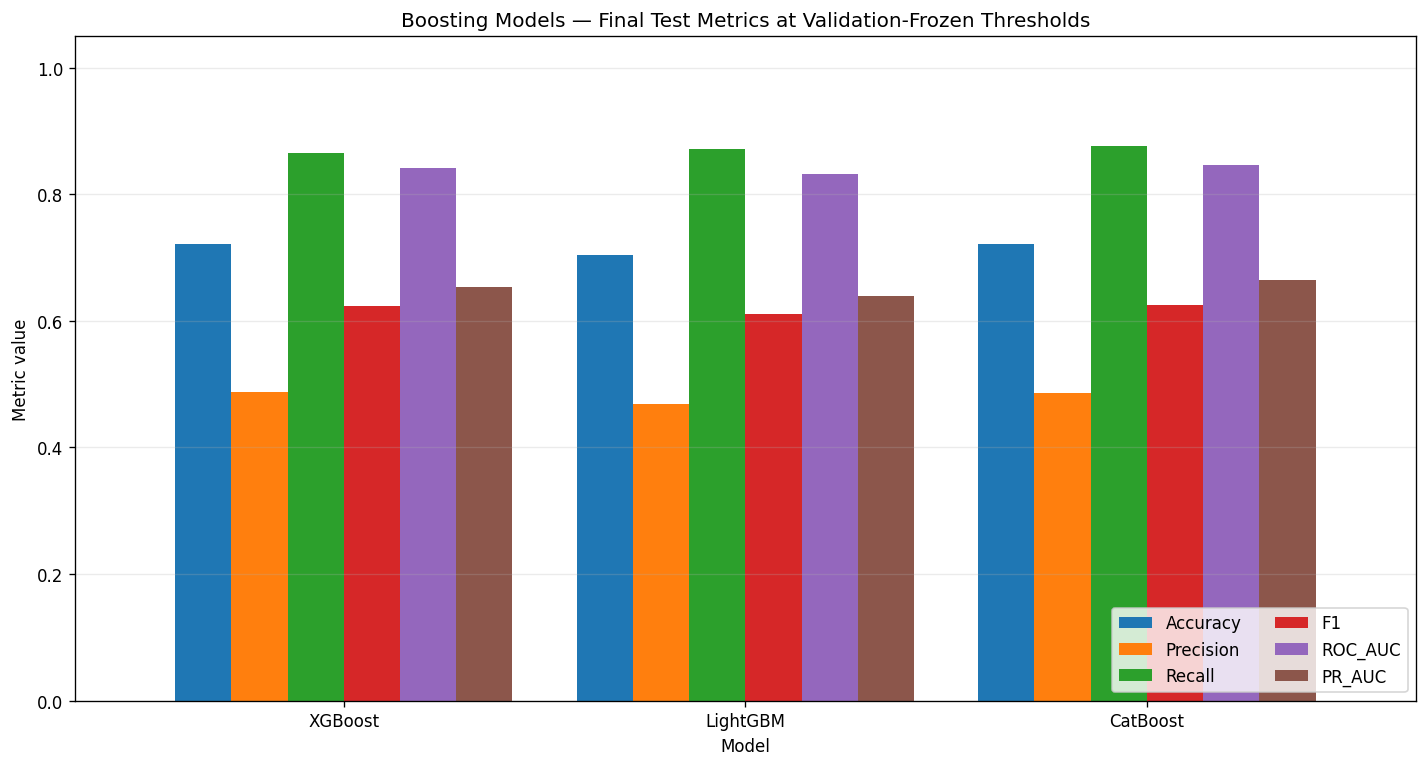

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/model_comparison_02_boosting_selected_threshold_test_metrics.png')

In [8]:
boosting_selected_test = ordered_concat([
    normalize_metrics(load_explicit(BOOSTING_SELECTED_TEST_FILES[model]), model, "test", "selected_threshold_frozen_from_validation")
    for model in BOOSTING_MODEL_ORDER
], BOOSTING_MODEL_ORDER)
assert_scope(boosting_selected_test, BOOSTING_MODEL_ORDER, "Boosting frozen-threshold test")
validation_thresholds = boosting_selected_validation.set_index(boosting_selected_validation["Model"].astype(str))["Threshold"]
test_thresholds = boosting_selected_test.set_index(boosting_selected_test["Model"].astype(str))["Threshold"]
for model in BOOSTING_MODEL_ORDER:
    if not np.isclose(test_thresholds.loc[model], validation_thresholds.loc[model]):
        raise ValueError(f"Test threshold for {model} does not match validation-selected threshold.")
    if not np.isclose(test_thresholds.loc[model], EXPECTED_SELECTED_THRESHOLDS[model]):
        raise ValueError(f"Test threshold for {model} differs from approved frozen threshold.")
boosting_selected_test["Threshold_Source"] = "validation"
save_table(boosting_selected_test, "boosting_selected_threshold_test_comparison.csv", "Final boosting test comparison with validation-frozen thresholds")

plot_metric_benchmark(boosting_selected_test, BOOSTING_MODEL_ORDER, "Boosting Models — Final Test Metrics at Validation-Frozen Thresholds")
save_figure("model_comparison_02_boosting_selected_threshold_test_metrics.png")


## 9. Section F — Default-versus-Selected Validation Delta


In [9]:
default_boosting = five_model_default[five_model_default["Model"].astype(str).isin(BOOSTING_MODEL_ORDER)].copy()
default_boosting["Model"] = default_boosting["Model"].astype(str)
selected_boosting = boosting_selected_validation.copy()
selected_boosting["Model"] = selected_boosting["Model"].astype(str)
delta_base = default_boosting.merge(selected_boosting, on="Model", suffixes=("_Default", "_Selected"), validate="one_to_one")
delta_rows = []
for _, row in delta_base.iterrows():
    output = {
        "Model": row["Model"],
        "Default_Threshold": row["Threshold_Default"],
        "Selected_Threshold": row["Threshold_Selected"],
        "Validation_Recall_Target": RECALL_TARGET,
        "Meets_Recall_Target": bool(row["Recall_Selected"] >= RECALL_TARGET),
    }
    for metric in ["Accuracy", "Precision", "Recall", "F1", "TP", "FP", "TN", "FN"]:
        output[f"Default_{metric}"] = row[f"{metric}_Default"]
        output[f"Selected_{metric}"] = row[f"{metric}_Selected"]
        output[f"Delta_{metric}"] = row[f"{metric}_Selected"] - row[f"{metric}_Default"]
    delta_rows.append(output)
boosting_delta = pd.DataFrame(delta_rows)
boosting_delta["Model"] = pd.Categorical(boosting_delta["Model"], categories=BOOSTING_MODEL_ORDER, ordered=True)
boosting_delta = boosting_delta.sort_values("Model").reset_index(drop=True)
assert_scope(boosting_delta, BOOSTING_MODEL_ORDER, "Boosting default-versus-selected delta")
save_table(boosting_delta, "boosting_default_vs_selected_validation_delta.csv", "Boosting default-versus-selected validation deltas")


Boosting default-versus-selected validation deltas: shape=(3, 29); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\boosting_default_vs_selected_validation_delta.csv


,Model,Default_Threshold,Selected_Threshold,Validation_Recall_Target,Meets_Recall_Target,Default_Accuracy,Selected_Accuracy,Delta_Accuracy,Default_Precision,Selected_Precision,...,Delta_TP,Default_FP,Selected_FP,Delta_FP,Default_TN,Selected_TN,Delta_TN,Default_FN,Selected_FN,Delta_FN
0,XGBoost,0.5,0.38,0.85,True,0.761364,0.731061,-0.030303,0.533493,0.495833,...,15,195,242,47,581,534,-47,57,42,-15
1,LightGBM,0.5,0.27,0.85,True,0.779356,0.724432,-0.054924,0.562334,0.488798,...,28,165,251,86,611,525,-86,68,40,-28
2,CatBoost,0.5,0.38,0.85,True,0.764205,0.741477,-0.022727,0.538272,0.507431,...,21,187,232,45,589,544,-45,62,41,-21


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/boosting_default_vs_selected_validation_delta.csv')

## 10. Required Boosting Threshold Figure


Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_comparison_08_boosting_threshold_sensitivity_recall_validation.png


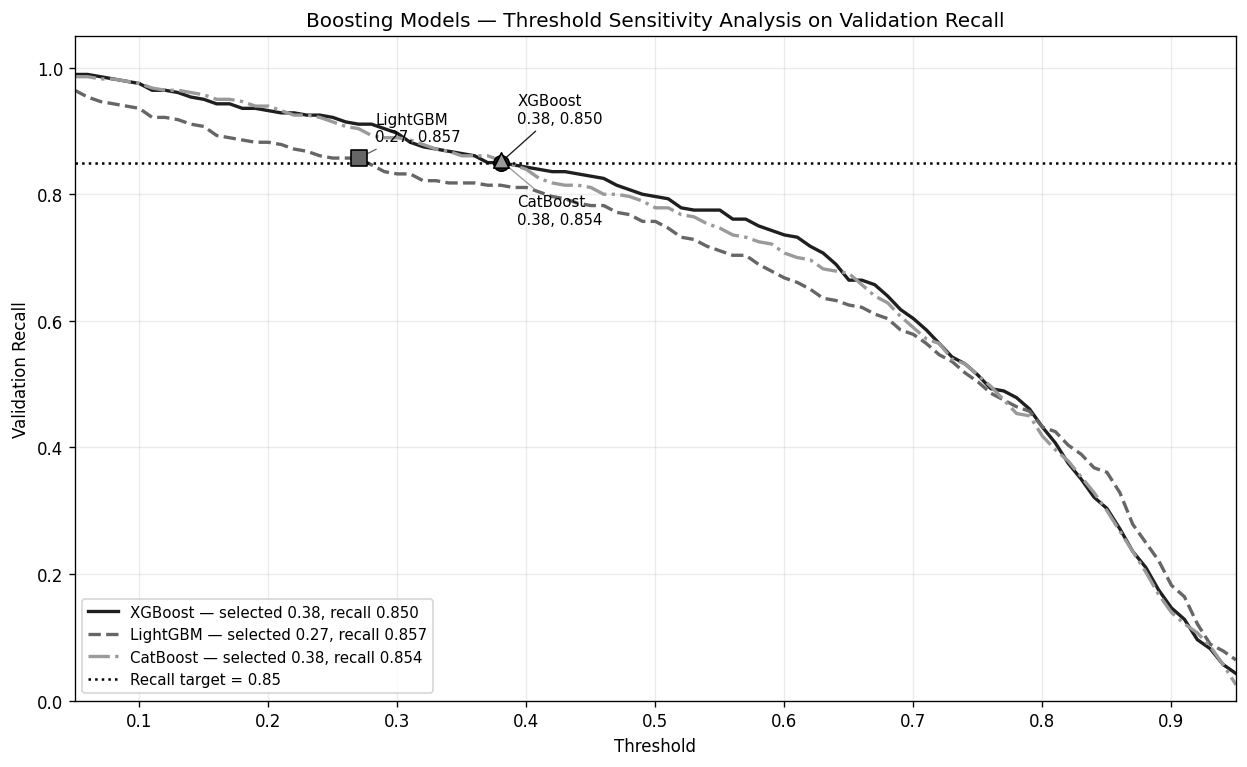

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/model_comparison_08_boosting_threshold_sensitivity_recall_validation.png')

In [10]:
line_styles = {"XGBoost": "-", "LightGBM": "--", "CatBoost": "-."}
markers = {"XGBoost": "o", "LightGBM": "s", "CatBoost": "^"}
colors = {"XGBoost": "#1f1f1f", "LightGBM": "#666666", "CatBoost": "#9a9a9a"}
annotation_offsets = {"XGBoost": (10, 24), "LightGBM": (10, 10), "CatBoost": (10, -38)}

fig, ax = plt.subplots(figsize=(10.5, 6.5))
for model in BOOSTING_MODEL_ORDER:
    curve = boosting_threshold[boosting_threshold["Model"].astype(str) == model].sort_values("Threshold")
    selected = boosting_selected_validation[boosting_selected_validation["Model"].astype(str) == model].iloc[0]
    label = f"{model} — selected {selected['Threshold']:.2f}, recall {selected['Recall']:.3f}"
    ax.plot(curve["Threshold"], curve["Recall"], color=colors[model], linestyle=line_styles[model], linewidth=2.0, label=label)
    ax.scatter(selected["Threshold"], selected["Recall"], color=colors[model], marker=markers[model], s=85, edgecolor="black", zorder=5)
    ax.annotate(f"{model}\n{selected['Threshold']:.2f}, {selected['Recall']:.3f}",
                (selected["Threshold"], selected["Recall"]), xytext=annotation_offsets[model],
                textcoords="offset points", fontsize=9,
                arrowprops={"arrowstyle": "-", "color": colors[model], "linewidth": 0.8})
ax.axhline(RECALL_TARGET, color="black", linestyle=":", linewidth=1.5, label="Recall target = 0.85")
ax.set_title("Boosting Models — Threshold Sensitivity Analysis on Validation Recall")
ax.set_xlabel("Threshold")
ax.set_ylabel("Validation Recall")
ax.set_xlim(0.05, 0.95)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend(loc="lower left", fontsize=9)
save_figure("model_comparison_08_boosting_threshold_sensitivity_recall_validation.png")


## 11. Output and source-safety validation


In [11]:
expected_csv = [
    "core_research_default_threshold_validation_comparison.csv",
    "five_model_default_threshold_validation_benchmark.csv",
    "boosting_threshold_sensitivity_validation_combined.csv",
    "boosting_selected_threshold_validation_comparison.csv",
    "boosting_selected_threshold_test_comparison.csv",
    "boosting_default_vs_selected_validation_delta.csv",
]
expected_figures = [
    "model_comparison_01_five_model_default_threshold_validation_metrics.png",
    "model_comparison_02_boosting_selected_threshold_test_metrics.png",
    "model_comparison_08_boosting_threshold_sensitivity_recall_validation.png",
]
output_check = pd.DataFrame([
    {"File": name, "Exists": (DATA_REPORTS_DIR / name).exists()} for name in expected_csv
] + [
    {"File": name, "Exists": (FIGURES_DIR / name).exists()} for name in expected_figures
])
display(output_check)
if not output_check["Exists"].all():
    raise FileNotFoundError("Notebook 05 expected outputs are incomplete.")

forbidden_selected_models = {"Logistic Regression", "Random Forest"}
for table_name, table in {
    "boosting threshold sensitivity": boosting_threshold,
    "boosting selected validation": boosting_selected_validation,
    "boosting selected test": boosting_selected_test,
    "boosting delta": boosting_delta,
}.items():
    if forbidden_selected_models.intersection(set(table["Model"].astype(str))):
        raise ValueError(f"Historical core selected-threshold models leaked into {table_name}.")

print("Notebook 05 completed without model training, preprocessing calls, test threshold scanning, or broad selected-output discovery.")


,File,Exists
0,core_research_default_threshold_validation_com...,True
1,five_model_default_threshold_validation_benchm...,True
2,boosting_threshold_sensitivity_validation_comb...,True
3,boosting_selected_threshold_validation_compari...,True
4,boosting_selected_threshold_test_comparison.csv,True
5,boosting_default_vs_selected_validation_delta.csv,True
6,model_comparison_01_five_model_default_thresho...,True
7,model_comparison_02_boosting_selected_threshol...,True
8,model_comparison_08_boosting_threshold_sensiti...,True


Notebook 05 completed without model training, preprocessing calls, test threshold scanning, or broad selected-output discovery.
